# 02 · Filtro, latidos y serie RR

**Pregunta de este notebook.** ¿Cómo se pasa del ECG crudo a una serie RR confiable? Cada paso responde a un problema que se vio en `01`:

1. **Filtro**: sacar la deriva de línea de base y el ruido de alta frecuencia sin deformar el latido.
2. **Latidos**: ubicar cada pico R. Se comparan las marcas de la base con un detector propio (Pan-Tompkins), se encuentra dónde falla cada uno y se mejora el detector propio.
3. **Refinamiento**: a 100 Hz el pico R cae en una grilla de 10 ms; se mide si vale la pena corregirlo.
4. **Limpieza del RR**: corregir los intervalos imposibles (latidos perdidos, de más o ectópicos).

Nada de este notebook usa las etiquetas de apnea: todas las decisiones salen de las señales de los 47 registros de desarrollo.

In [1]:
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import welch

from src.config import ECG_FILTER, SPLIT_CSV
from src.data import load_ecg, load_qrs
from src.features.edr import qrs_reference
from src.preprocessing.filters import (apply_zero_phase, beat_spectrum, cumulative_energy_freq,
                                       design_bandpass, frequency_response, meets_spec)
from src.qrs.beats import record_beats
from src.qrs.pan_tompkins import (detect_r_peaks, pan_tompkins_signals, r_peaks_from_marks,
                                  refine_peaks_parabolic, validate_against_reference)
from src.qrs.quantization import two_phase_peaks
from src.qrs.rr_clean import clean_rr, minute_quality
from src.viz.plots import ANCHO, APNEA, COLORES_CAT, GRIS, NORMAL, save, setup

setup()
split = pd.read_csv(SPLIT_CSV)
DEV = split[split.set == "dev"].record.tolist()
FS = 100.0

## 1. El filtro

**Qué tiene que hacer** (de `01`): sacar la deriva por debajo de ~0,5 Hz y el ruido por encima de ~40 Hz, incluida la línea de 50 Hz, sin tocar el latido.

**Especificación**, sacada de los registros de desarrollo:
- **Límite inferior de la banda de paso**: la frecuencia cardíaca más baja, medida como el percentil 1 de la frecuencia instantánea (1/RR) de todos los latidos. Por debajo de ella no hay energía del latido, solo deriva.
- **Límite superior de la banda de paso**: la frecuencia por debajo de la cual está el 99 % de la energía del latido mediano de cada registro, tomando el percentil 95 entre registros (el registro más exigente es un caso aislado).
- En la banda de paso la atenuación tiene que ser de **1 dB o menos**, y a 0,1 Hz (deriva lenta) de **20 dB o más**.

**Diseño.** Butterworth pasabanda (respuesta plana en la banda de paso) aplicado **ida y vuelta** (`sosfiltfilt`): la fase total es cero, así que no corre el pico R ni deforma el QRS, y la ganancia efectiva es |H(f)|². El corte alto se elige por debajo de 50 Hz, donde está la interferencia; el bajo, en 0,5 Hz, el valor habitual para monitoreo de ECG. Se elige el **menor orden** que cumple la especificación (menos oscilación en el tiempo y menos transitorio en los bordes).

In [2]:
f99, fc = [], []
for rec in DEV:
    ecg, fs = load_ecg(rec)
    qrs = load_qrs(rec)
    off, sign = qrs_reference(ecg, qrs, fs)
    peaks = np.rint(r_peaks_from_marks(ecg, qrs, fs, off, sign)[0] * fs).astype(int)
    f, p = beat_spectrum(ecg, peaks, fs)
    f99.append(cumulative_energy_freq(f, p, 0.99))
    _, rr, corr = clean_rr(peaks / fs)
    fc.append(1 / rr[~corr])
F_FC_MIN = float(np.percentile(np.concatenate(fc), 1))
F_QRS = float(np.percentile(f99, 95))
print(f"límite inferior: {F_FC_MIN:.2f} Hz ({60 * F_FC_MIN:.0f} lpm) · límite superior: {F_QRS:.1f} Hz")

filas = []
for lo in (0.3, 0.5, 0.7):
    for hi in (35, 40, 45):
        orden = next((n for n in range(1, 9)
                      if meets_spec(design_bandpass(FS, lo, hi, n), FS, (F_FC_MIN, F_QRS), {0.1: 20}, 1.0)), None)
        filas.append({"corte bajo (Hz)": lo, "corte alto (Hz)": hi, "menor orden que cumple": orden})
pd.DataFrame(filas).pivot(index="corte bajo (Hz)", columns="corte alto (Hz)", values="menor orden que cumple")

límite inferior: 0.77 Hz (46 lpm) · límite superior: 41.8 Hz


corte alto (Hz),35,40,45
corte bajo (Hz),,,
0.3,NaN,NaN,3.0
0.5,NaN,NaN,3.0
0.7,NaN,NaN,NaN


Con corte alto de 35 o 40 Hz ningún orden cumple: el filtro atenuaría parte del QRS. Con 45 Hz, el menor orden que cumple con el corte bajo de 0,5 Hz es 3: **pasabanda Butterworth 0,5–45 Hz, orden 3, ida y vuelta**.

atenuación en los límites de la banda de paso: {'0.77 Hz': 0.62, '41.79 Hz': 0.39} · a 0,1 Hz: 84.0 dB


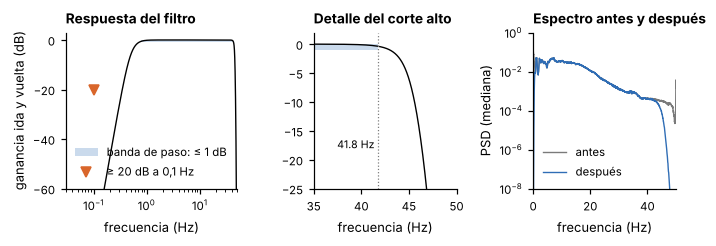

In [3]:
sos = design_bandpass(FS, *ECG_FILTER)
r = frequency_response(sos, FS, n=2 ** 16)
fig, ax = plt.subplots(1, 3, figsize=(ANCHO, 2.3), gridspec_kw={"width_ratios": [1.2, 1, 1]})
for a, xlim, xscale in ((ax[0], (0.03, 50), "log"), (ax[1], (35, 50), "linear")):
    a.plot(r["f"], r["ganancia_db_ida_vuelta"], color="black")
    a.fill_between([F_FC_MIN, F_QRS], -1, 0, color=NORMAL, alpha=0.25, lw=0, label="banda de paso: ≤ 1 dB")
    a.plot([0.1], [-20], marker="v", color=APNEA, ls="none", label="≥ 20 dB a 0,1 Hz")
    a.set(xscale=xscale, xlim=xlim, xlabel="frecuencia (Hz)")
ax[0].set(ylim=(-60, 3), ylabel="ganancia ida y vuelta (dB)", title="Respuesta del filtro")
ax[0].legend(loc="lower right")
ax[1].set(ylim=(-25, 2), title="Detalle del corte alto")
ax[1].axvline(F_QRS, color=GRIS, ls=":", lw=0.8)
ax[1].text(F_QRS - 0.4, -18, f"{F_QRS:.1f} Hz", ha="right", fontsize=7)
psd_antes, psd_despues = [], []
for rec in DEV:
    ecg, fs = load_ecg(rec)
    ff, p0 = welch(ecg - ecg.mean(), fs=fs, nperseg=4096)
    _, p1 = welch(apply_zero_phase(ecg, sos), fs=fs, nperseg=4096)
    norma = np.trapezoid(p0, ff)                       # los dos con la potencia del crudo
    psd_antes.append(p0 / norma); psd_despues.append(p1 / norma)
ax[2].semilogy(ff, np.median(psd_antes, axis=0), color=GRIS, label="antes")
ax[2].semilogy(ff, np.median(psd_despues, axis=0), color=NORMAL, label="después")
ax[2].set(xlabel="frecuencia (Hz)", ylabel="PSD (mediana)", title="Espectro antes y después", xlim=(0, 50),
          ylim=(1e-8, 1))
ax[2].legend(loc="lower left")
fig.tight_layout()
save(fig, "02_filtro_respuesta")
print("atenuación en los límites de la banda de paso:",
      {f"{x:.2f} Hz": round(float(-np.interp(x, r["f"], r["ganancia_db_ida_vuelta"])), 2) for x in (F_FC_MIN, F_QRS)},
      "· a 0,1 Hz:", round(float(-np.interp(0.1, r["f"], r["ganancia_db_ida_vuelta"])), 1), "dB")

**Qué se ve.** La respuesta queda dentro de la especificación: casi plana entre la frecuencia cardíaca más baja y el límite del QRS, y con más de 20 dB de atenuación a 0,1 Hz. En 50 Hz la atenuación es total: el diseño digital por transformación bilineal ubica un cero justo en la frecuencia de Nyquist, donde está la interferencia. En el espectro (los dos normalizados por la potencia del ECG crudo) desaparecen la potencia por debajo de 0,5 Hz y la subida por encima de 45 Hz.

En el tiempo, sobre los dos registros de `01` con deriva e interferencia:

PosixPath('/home/user/TP-PSB-G8/informe/figuras/02_filtro_tiempo.png')

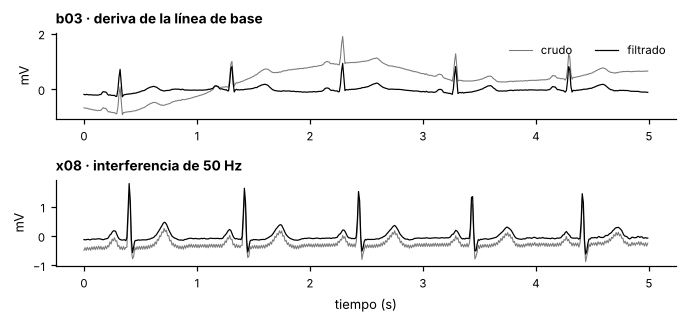

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(ANCHO, 3.0))
for ax, (rec, t0, titulo) in zip(axs, [("b03", 3 * 3600 + 600, "b03 · deriva de la línea de base"),
                                       ("x08", 2 * 3600, "x08 · interferencia de 50 Hz")]):
    ecg, fs = load_ecg(rec)
    i = slice(int(t0 * fs), int((t0 + 5) * fs))
    t = np.arange(i.stop - i.start) / fs
    ax.plot(t, ecg[i], color=GRIS, lw=0.7, label="crudo")
    ax.plot(t, apply_zero_phase(ecg, sos)[i], color="black", lw=0.8, label="filtrado")
    ax.set(title=titulo, ylabel="mV")
axs[0].legend(loc="upper right", ncol=2)
axs[1].set_xlabel("tiempo (s)")
fig.tight_layout()
save(fig, "02_filtro_tiempo")

La deriva desaparece y la señal queda centrada en cero; la alternancia de 50 Hz se elimina. Los picos R quedan en el mismo lugar (fase cero) y con la misma forma.

## 2. Los latidos

Hay dos fuentes posibles para ubicar cada latido:

- **Las marcas de la base** (archivos `.qrs`). Las generó un detector automático y **no están revisadas** por un experto. No marcan el pico R sino un punto del QRS, así que el pico se busca a ±30 ms de cada marca con la polaridad del registro.
- **Un detector propio**: el algoritmo de Pan y Tompkins (1985) adaptado a 100 Hz. Sus etapas, sobre 6 s de `a03`:

PosixPath('/home/user/TP-PSB-G8/informe/figuras/02_pan_tompkins.png')

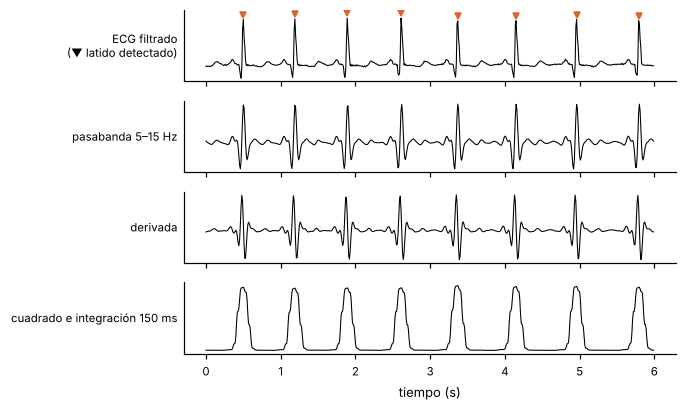

In [5]:
ecg, fs = load_ecg("a03")
x = apply_zero_phase(ecg, sos)
bp, d, mwi = pan_tompkins_signals(x, fs)
k = detect_r_peaks(x, fs)
i = slice(int(3600 * fs), int(3606 * fs))
t = np.arange(i.stop - i.start) / fs
fig, axs = plt.subplots(4, 1, figsize=(ANCHO, 3.8), sharex=True)
etapas = [(x, ""), (bp, "pasabanda 5–15 Hz"), (d, "derivada"), (mwi, "cuadrado e integración 150 ms")]
for ax, (s, nombre) in zip(axs, etapas):
    ax.plot(t, s[i], color="black", lw=0.7)
    if nombre:
        ax.set_ylabel(nombre, rotation=0, ha="right", va="center", fontsize=7.5)
    ax.set_yticks([])
kk = k[(k >= i.start) & (k < i.stop)]
axs[0].plot((kk - i.start) / fs, x[kk] + 0.3, "v", color=APNEA, ms=4)
axs[0].set_ylabel("ECG filtrado\n(▼ latido detectado)", rotation=0, ha="right", va="center", fontsize=7.5)
axs[-1].set_xlabel("tiempo (s)")
fig.tight_layout()
save(fig, "02_pan_tompkins")

**Cómo funciona.** El pasabanda de 5–15 Hz se queda con la banda donde el QRS tiene más energía y saca las ondas P y T, más lentas. La derivada resalta las pendientes empinadas del QRS. El cuadrado la hace positiva (así el detector no depende de la polaridad del R) y realza las pendientes grandes sobre las chicas. La integración en 150 ms (el ancho típico de un QRS) junta toda la energía de cada complejo en un solo pulso. Sobre ese pulso, un **umbral adaptativo** que sigue los niveles de señal y de ruido decide si hay un latido; además hay un período refractario de 200 ms, un descarte de ondas T (picos a menos de 360 ms del anterior con menos de la mitad de su pendiente) y una búsqueda hacia atrás cuando pasa demasiado tiempo sin latidos. Las etapas lineales están centradas, así que no introducen retardo.

### ¿Coinciden las dos fuentes?

Se corren las marcas de la base y el detector propio en su versión clásica en los 47 registros de desarrollo. Para cada latido del detector se busca la marca de la base más cercana. (La versión mejorada, que se arma más abajo, se calcula en la misma pasada.)

clasico: detecciones a ≤30 ms de una marca 96.8 %, a ≤150 ms 97.2 %
mejorado: detecciones a ≤30 ms de una marca 98.4 %, a ≤150 ms 98.7 %


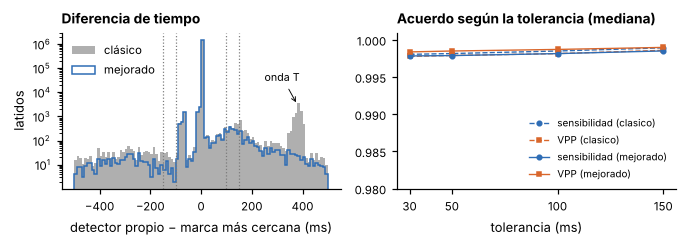

In [6]:
import src.qrs.pan_tompkins as pt_mod

def comparar(rec):
    ecg, fs = load_ecg(rec)
    x = apply_zero_phase(ecg, design_bandpass(fs, *ECG_FILTER))
    qrs = load_qrs(rec)
    off, sign = qrs_reference(x, qrs, fs)
    tb = r_peaks_from_marks(x, qrs, fs, off, sign, refine=False)[0]
    fila, difs = {"record": rec, "corr_base": 100 * clean_rr(tb)[2].mean()}, {}
    for nombre, mejorado in (("clasico", False), ("mejorado", True)):
        tp = detect_r_peaks(x, fs, improved=mejorado) / fs
        j = np.clip(np.searchsorted(tb, tp), 1, len(tb) - 1)
        difs[nombre] = np.where(np.abs(tp - tb[j - 1]) < np.abs(tp - tb[j]), tp - tb[j - 1], tp - tb[j])
        fila[f"corr_{nombre}"] = 100 * clean_rr(tp)[2].mean()
        for tol in (0.03, 0.05, 0.10, 0.15):
            v = validate_against_reference(np.rint(tp * fs), np.rint(tb * fs), fs, tol)
            fila[f"Se_{nombre}_{int(1000 * tol)}"], fila[f"VPP_{nombre}_{int(1000 * tol)}"] = v["Se"], v["VPP"]
    return fila, difs

with ProcessPoolExecutor(4) as ex:
    res = list(ex.map(comparar, DEV))
comp = pd.DataFrame([r for r, _ in res]).merge(split[["record", "set", "category"]])
difs = {n: np.concatenate([d[n] for _, d in res]) for n in ("clasico", "mejorado")}

fig, ax = plt.subplots(1, 2, figsize=(ANCHO, 2.3))
bins = np.arange(-500, 505, 10)
ax[0].hist(1000 * difs["clasico"][np.abs(difs["clasico"]) < 0.5], bins=bins, color=GRIS, alpha=0.6, label="clásico")
ax[0].hist(1000 * difs["mejorado"][np.abs(difs["mejorado"]) < 0.5], bins=bins, color=NORMAL, histtype="step",
           lw=1, label="mejorado")
ax[0].set(yscale="log", xlabel="detector propio − marca más cercana (ms)", ylabel="latidos",
          title="Diferencia de tiempo")
for tol in (100, 150):
    ax[0].axvline(-tol, color=GRIS, ls=":", lw=0.8); ax[0].axvline(tol, color=GRIS, ls=":", lw=0.8)
ax[0].annotate("onda T", xy=(380, 3000), xytext=(250, 3e4), fontsize=7, arrowprops=dict(arrowstyle="->", lw=0.6))
ax[0].legend(loc="upper left")
tols = [30, 50, 100, 150]
for nombre, ls in (("clasico", "--"), ("mejorado", "-")):
    ax[1].plot(tols, [comp[f"Se_{nombre}_{t}"].median() for t in tols], "o" + ls, color=NORMAL, ms=3,
               label=f"sensibilidad ({nombre})")
    ax[1].plot(tols, [comp[f"VPP_{nombre}_{t}"].median() for t in tols], "s" + ls, color=APNEA, ms=3,
               label=f"VPP ({nombre})")
ax[1].set(xlabel="tolerancia (ms)", ylim=(0.98, 1.001), title="Acuerdo según la tolerancia (mediana)", xticks=tols)
ax[1].legend(loc="lower right", fontsize=6.5)
fig.tight_layout()
save(fig, "02_acuerdo_detectores")
for n in difs:
    print(f"{n}: detecciones a ≤30 ms de una marca {100 * np.mean(np.abs(difs[n]) <= 0.03):.1f} %, "
          f"a ≤150 ms {100 * np.mean(np.abs(difs[n]) <= 0.15):.1f} %")

**Qué se ve.** Cuando las dos fuentes encuentran el mismo latido, lo ubican a menos de 30 ms una de otra (el eje vertical es logarítmico). Entre 30 y 150 ms cae solo un 0,5 % más de las detecciones; el resto está lejos, como el grupo a +380 ms del detector clásico, que son ondas T. Es decir, las diferencias son **latidos que una fuente encontró y la otra no**, no latidos ubicados distinto. Por eso **la tolerancia casi no cambia el resultado**: la sensibilidad (fracción de marcas de la base que el detector también encuentra) y el valor predictivo positivo (VPP: fracción de detecciones con una marca cerca) varían menos de un punto entre 30 y 150 ms. Se usa 100 ms, por debajo de los 150 ms de la norma de evaluación de detectores (ANSI/AAMI EC57).

¿Quién se equivoca en las diferencias? Se revisaron a mano 50 discrepancias del detector clásico, elegidas al azar en desarrollo (`docs/revision_qrs_50.csv`):

In [7]:
rev = pd.read_csv(ROOT / "docs" / "revision_qrs_50.csv")
rev["tipo"] = rev.tipo.map({"FP": "solo lo marca el detector", "FN": "solo lo marca la base"})
pd.crosstab(rev.clasificacion, rev.tipo, margins=True, margins_name="total")

tipo,solo lo marca el detector,solo lo marca la base,total
clasificacion,,,
dudoso,8,3,11
error de las marcas de la base,18,0,18
error del detector,20,1,21
total,46,4,50


Hay errores de los dos lados: 18 latidos verdaderos que la base se saltea y 21 errores del detector. Estos son los patrones:

PosixPath('/home/user/TP-PSB-G8/informe/figuras/02_casos_detectores.png')

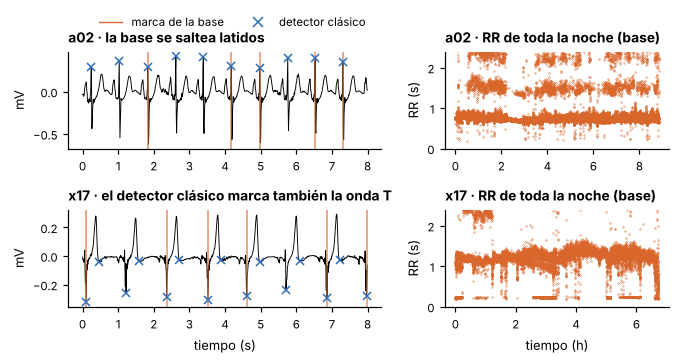

In [8]:
def tramo(rec):
    ecg, fs = load_ecg(rec)
    x = apply_zero_phase(ecg, sos)
    qrs = load_qrs(rec)
    off, sign = qrs_reference(x, qrs, fs)
    tb = r_peaks_from_marks(x, qrs, fs, off, sign, refine=False)[0]
    return x, fs, tb

fig, axs = plt.subplots(2, 2, figsize=(ANCHO, 3.2), gridspec_kw={"width_ratios": [1.4, 1]})
for row, (rec, t0, titulo) in enumerate([("a02", 7535, "a02 · la base se saltea latidos"),
                                         ("x17", 4157, "x17 · el detector clásico marca también la onda T")]):
    x, fs, tb = tramo(rec)
    tp = detect_r_peaks(x, fs, improved=False) / fs
    i = slice(int(t0 * fs), int((t0 + 8) * fs))
    axs[row, 0].plot(np.arange(i.start, i.stop) / fs - t0, x[i], color="black", lw=0.6)
    for tt in tb[(tb >= t0) & (tb < t0 + 8)]:
        axs[row, 0].axvline(tt - t0, color=APNEA, lw=1.2, alpha=0.6)
    sel = tp[(tp >= t0) & (tp < t0 + 8)]
    axs[row, 0].plot(sel - t0, x[np.rint(sel * fs).astype(int)], "x", color=NORMAL, ms=5)
    axs[row, 0].set(title=titulo, ylabel="mV")
    axs[row, 1].plot(tb[1:] / 3600, np.diff(tb), ".", ms=0.6, color=APNEA)
    axs[row, 1].set(ylim=(0, 2.4), ylabel="RR (s)", title=f"{rec} · RR de toda la noche (base)")
axs[1, 0].set_xlabel("tiempo (s)"); axs[1, 1].set_xlabel("tiempo (h)")
axs[0, 0].plot([], [], color=APNEA, label="marca de la base")
axs[0, 0].plot([], [], "x", color=NORMAL, label="detector clásico")
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="upper center", ncol=2, bbox_to_anchor=(0.35, 1.03))
fig.tight_layout()
save(fig, "02_casos_detectores")

**Qué se ve.**
- **a02**: el QRS tiene una onda R chica y una S profunda, y la base se saltea latidos enteros. En el RR de toda la noche aparece una segunda banda al doble del RR normal (~1,5 s). El detector propio los encuentra.
- **x17**: el QRS es chico e invertido y la onda T es grande y termina con una bajada empinada. El detector clásico marca además el final de la T.
- En `c03` y `x04` las dos fuentes dejan ~7,5 % de RR corregidos: encuentran los mismos latidos, pero el ritmo cambia de golpe (de ~1,4 a ~0,9 s en pocos latidos). No es un error de detección; la limpieza del RR (sección 4) igual los corrige.

Las marcas de la base no se pueden corregir, pero el detector propio sí. Para eso hay que entender **dónde falla**. Se buscaron los registros donde el detector clásico deja más RR corregidos que la base y se miraron sus detecciones de más. Aparecen dos problemas:

PosixPath('/home/user/TP-PSB-G8/informe/figuras/02_fallas_detector.png')

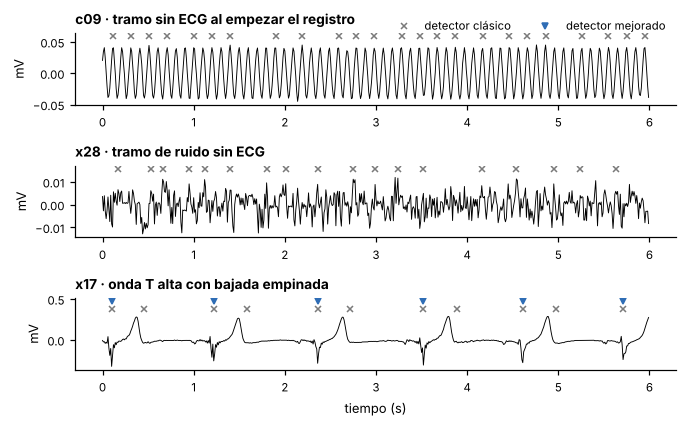

In [9]:
casos_pt = [("c09", 240, "c09 · tramo sin ECG al empezar el registro"),
            ("x28", 389.5, "x28 · tramo de ruido sin ECG"),
            ("x17", 4157, "x17 · onda T alta con bajada empinada")]
fig, axs = plt.subplots(3, 1, figsize=(ANCHO, 4.0))
for ax, (rec, t0, titulo) in zip(axs, casos_pt):
    x, fs, tb = tramo(rec)
    i = slice(int(t0 * fs), int((t0 + 6) * fs))
    ax.plot(np.arange(i.start, i.stop) / fs - t0, x[i], color="black", lw=0.6)
    for nombre, mejorado, mk, col, dy in (("clásico", False, "x", GRIS, 0), ("mejorado", True, "v", NORMAL, 1)):
        k = detect_r_peaks(x, fs, improved=mejorado)
        k = k[(k >= i.start) & (k < i.stop)]
        top = np.max(x[i]) + 0.15 * np.ptp(x[i]) * (1 + dy)
        ax.plot((k - i.start) / fs, np.full(len(k), top), mk, color=col, ms=4, label=f"detector {nombre}")
    ax.set(title=titulo, ylabel="mV")
axs[0].legend(loc="upper right", ncol=2, bbox_to_anchor=(1, 1.35))
axs[-1].set_xlabel("tiempo (s)")
fig.tight_layout()
save(fig, "02_fallas_detector")

**Problema 1: tramos sin ECG.** Varios registros (sobre todo controles) empiezan con 10 a 20 minutos sin ECG: una oscilación regular de ~7 Hz y 0,04 mV, probablemente antes de conectar los electrodos (`c09`), y otros tienen tramos de ruido de ~0,01 mV (`x28`). El umbral del detector clásico se adapta al nivel de la señal, así que en esos tramos baja hasta el nivel del ruido y marca un "latido" cada 0,2–0,3 s (el período refractario). La base no marca nada ahí.

**Problema 2: ondas T altas.** El detector clásico descarta un pico como onda T si aparece a menos de 360 ms del QRS anterior y tiene menos de la mitad de su pendiente. En `x17` las dos condiciones fallan: con ritmo lento (~50 latidos por minuto) la T termina después de los 360 ms, y su bajada es tan empinada como el QRS, que es chico.

### Cómo se mejoró el detector propio

Cada cambio responde a uno de los dos problemas y usa una propiedad del QRS que el ruido o la onda T no tienen (`src/qrs/pan_tompkins.py`, parámetros en `src/config.py`):

| Problema | Cambio | Propiedad que usa |
|---|---|---|
| Sin ECG | **Pulso aislado**: un candidato solo puede ser QRS si su prominencia en la señal integrada es al menos la mitad de su altura | Entre dos QRS la señal integrada vuelve casi a cero; en una oscilación o en ruido, no |
| Sin ECG | **Piso de energía**: el pico de la señal integrada tiene que superar el 5 % de la mediana de los QRS del registro (se estima con una primera pasada) | El ruido sin ECG tiene mucha menos energía que un QRS del mismo registro |
| Onda T | **Ventana de onda T según el ritmo**: el descarte se aplica hasta 0,5 RR medios después del QRS (mínimo 360 ms) | El intervalo QT se alarga cuando el ritmo es lento |
| Onda T | **Forma**: en esa ventana, un candidato que no se parece a los últimos 8 QRS (correlación < 0,5 en el pasabanda, ±100 ms) se descarta | Todos los QRS de una persona tienen casi la misma forma; la T, otra |
| Onda T | **Energía rápida**: en esa ventana, un candidato con menos del 30 % de la energía por encima de 20 Hz del QRS anterior se descarta | El QRS dura ~80 ms y tiene energía por encima de 20 Hz; la T es lenta y casi no tiene |

Un latido prematuro verdadero cae en la ventana de onda T, pero tiene forma y energía de QRS, así que no se descarta (`tests/test_pan_tompkins.py`).

¿Aporta cada cambio? Se saca uno por vez y se mide en desarrollo la fracción de RR corregidos:

In [10]:
VARIANTES = {
    "mejorado (completo)": {},
    "sin pulso aislado": {"QRS_PROMINENCE_MIN": 0.0},
    "sin piso de energía": {"QRS_FLOOR_FRAC": 0.0},
    "sin ventana según el ritmo": {"QRS_TWAVE_RR_FRAC": 0.0},
    "sin forma": {"QRS_TEMPLATE_CORR_MIN": -2.0},
    "sin energía rápida": {"QRS_HF_RATIO_MIN": 0.0},
}

DEFECTO = {k: getattr(pt_mod, k) for v in VARIANTES.values() for k in v}

def ablacion(args):
    rec, nombre = args
    for k, v in {**DEFECTO, **VARIANTES[nombre]}.items():   # cada proceso reutiliza el módulo
        setattr(pt_mod, k, v)
    ecg, fs = load_ecg(rec)
    x = apply_zero_phase(ecg, design_bandpass(fs, *ECG_FILTER))
    return rec, nombre, 100 * clean_rr(detect_r_peaks(x, fs) / fs)[2].mean()

with ProcessPoolExecutor(4) as ex:
    abl = pd.DataFrame(list(ex.map(ablacion, [(r, n) for n in VARIANTES for r in DEV])),
                       columns=["record", "variante", "corr"])
ab = abl.pivot(index="record", columns="variante", values="corr")
cd = comp.set_index("record").loc[DEV]
ab["clásico"], ab["base"] = cd.corr_clasico, cd.corr_base
tabla = pd.DataFrame({"% RR corregidos (mediana)": ab.median(), "% RR corregidos (media)": ab.mean(),
                      "registros > 1 punto peor que la base": (ab.sub(ab.base, axis=0) > 1).sum(),
                      "cuáles": [", ".join(ab.index[ab[c] > ab.base + 1]) for c in ab.columns]})
tabla.loc[["base", "clásico", *VARIANTES]].round(2)

,% RR corregidos (mediana),% RR corregidos (media),registros > 1 punto peor que la base,cuáles
variante,,,,
base,0.57,1.98,0,
clásico,0.63,3.21,10,"c01, c02, c09, c10, x04, x17, x18, x20, x28, x35"
mejorado (completo),0.36,0.88,0,
sin pulso aislado,0.42,0.91,0,
sin piso de energía,0.39,0.92,1,x28
sin ventana según el ritmo,0.44,0.92,0,
sin forma,0.46,0.96,0,
sin energía rápida,0.41,2.18,1,x17


Sacar cualquiera de los cambios empeora la mediana de RR corregidos. Los dos cambios para los tramos sin ECG se superponen en parte (cada uno por separado ya arregla la mayoría de los controles); el piso es el que resuelve el ruido de `x28`. Entre los de la onda T, la energía rápida es la decisiva: sin ella `x17` vuelve a quedar peor que la base y la media sube a 2,2 %. Con todos, **ningún registro de desarrollo queda más de un punto peor que la base**, contra 10 del detector clásico.

### Verificación

Los cambios se diseñaron mirando los registros de desarrollo donde el clásico fallaba. Se verifican de dos formas, también en desarrollo: que **ningún registro empeore** respecto de la base (incluidos los que no se usaron para diseñar, donde el clásico ya andaba bien) y la **revisión manual** de los 50 casos, que se hizo antes de diseñar los cambios. Test no se usa: queda para la evaluación final.

set,dev
mediana base,0.57
mediana clásico,0.63
mediana mejorado,0.36
registros > 1 pt peor que la base (clásico),10.00
registros > 1 pt peor que la base (mejorado),0.00
registros > 1 pt mejor que la base (mejorado),7.00


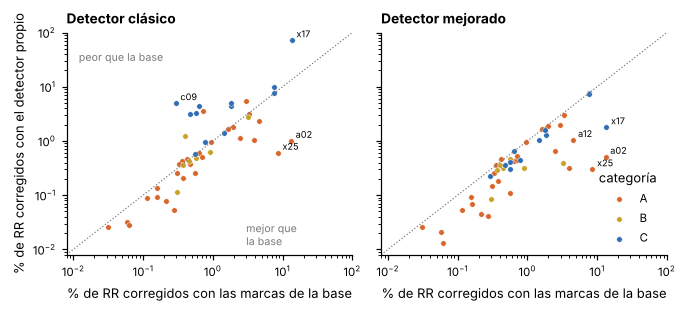

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(ANCHO, 2.9), sharey=True)
comp_dev = comp[comp.set == "dev"]
lim = (0.008, 100)
for ax, col, titulo in ((axs[0], "corr_clasico", "Detector clásico"), (axs[1], "corr_mejorado", "Detector mejorado")):
    for cat, g in comp_dev.groupby("category"):
        ax.scatter(g.corr_base.clip(lower=lim[0]), g[col].clip(lower=lim[0]), s=13,
                   color=COLORES_CAT[cat], edgecolor="white", lw=0.3, label=cat)
    ax.plot(lim, lim, color=GRIS, lw=0.8, ls=":")
    ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, title=titulo,
           xlabel="% de RR corregidos con las marcas de la base")
    etiquetas = ["x17", "c09", "a02", "x25"] if col == "corr_clasico" else ["x17", "a02", "x25", "a12"]
    for rec_ in etiquetas:
        r_ = comp.set_index("record").loc[rec_]
        ax.annotate(rec_, (r_.corr_base, r_[col]), fontsize=6, xytext=(3, 2), textcoords="offset points")
axs[0].set_ylabel("% de RR corregidos con el detector propio")
axs[0].text(0.012, 30, "peor que la base", fontsize=7, color=GRIS)
axs[0].text(3, 0.012, "mejor que\nla base", fontsize=7, color=GRIS)
axs[1].legend(loc="lower right", title="categoría")
fig.tight_layout()
save(fig, "02_detector_mejorado")
resumen = comp_dev.groupby("set").apply(lambda g: pd.Series({
    "mediana base": g.corr_base.median(), "mediana clásico": g.corr_clasico.median(),
    "mediana mejorado": g.corr_mejorado.median(),
    "registros > 1 pt peor que la base (clásico)": int((g.corr_clasico > g.corr_base + 1).sum()),
    "registros > 1 pt peor que la base (mejorado)": int((g.corr_mejorado > g.corr_base + 1).sum()),
    "registros > 1 pt mejor que la base (mejorado)": int((g.corr_mejorado < g.corr_base - 1).sum())}))
resumen.round(2).T

In [12]:
def detecta(rec, muestra):
    ecg, fs = load_ecg(rec)
    k = detect_r_peaks(apply_zero_phase(ecg, sos), fs)
    return bool(np.min(np.abs(k - muestra)) <= int(QRS_TOL * fs))

QRS_TOL = 0.10
rev["lo detecta el mejorado"] = [detecta(r, m) for r, m in zip(rev.record, rev["sample"])]
pd.crosstab([rev.tipo, rev.clasificacion], rev["lo detecta el mejorado"])

lo detecta el mejorado                                    False  True 
tipo                      clasificacion                               
solo lo marca el detector dudoso                              1      7
                          error de las marcas de la base      1     17
                          error del detector                 19      1
solo lo marca la base     dudoso                              3      0
                          error del detector                  1      0

**Qué se ve.**
- Con el detector mejorado **ningún registro de desarrollo queda más de un punto peor que la base**, y la mediana de RR corregidos baja de 0,57 % a 0,36 %. Los registros donde la base pierde latidos (`a02`, `a12`, `x14`, `x25`) mejoran mucho, y `x17` pasa de 72 % con el clásico a menos de 2 %.
- En la **revisión manual**, de las 20 detecciones del clásico que eran errores del detector, la versión mejorada elimina 19; de los 18 latidos verdaderos que la base se salteaba, conserva 17.

**Decisión: se usa el detector propio mejorado en todos los registros** (`src/qrs/beats.py`). Es el que deja menos RR imposibles y no depende de marcas sin revisar. Las marcas de la base quedan solo como comparación. Efecto sobre los minutos analizables (los que tienen 20 % o menos de RR corregidos, sección 4):

In [13]:
def minutos_validos(rec):
    out = {}
    for fuente in ("marks", "pt"):
        t, _, corr = clean_rr(record_beats(rec, fuente)["t_r"])
        out[fuente] = int(np.sum(minute_quality(t, corr, int(np.ceil(t[-1] / 60))) <= 0.2))
    return rec, out

with ProcessPoolExecutor(4) as ex:
    mv = dict(ex.map(minutos_validos, DEV))
comp["min_validos_base"] = comp.record.map(lambda r: mv[r]["marks"])
comp["min_validos_propio"] = comp.record.map(lambda r: mv[r]["pt"])
print("minutos con ≤ 20 % de RR corregidos — marcas de la base:", comp.min_validos_base.sum(),
      "· detector propio mejorado:", comp.min_validos_propio.sum())
(comp.assign(dif=comp.min_validos_propio - comp.min_validos_base)
     .sort_values("dif", ascending=False)[["record", "corr_base", "corr_mejorado", "min_validos_base",
                                           "min_validos_propio"]].round(1).head(10))

minutos con ≤ 20 % de RR corregidos — marcas de la base: 22485 · detector propio mejorado: 22991


,record,corr_base,corr_mejorado,min_validos_base,min_validos_propio
1,a02,13.2,0.5,314,531
36,x17,13.6,1.8,289,397
42,x25,8.5,0.3,464,510
8,a12,4.6,1.0,533,577
34,x14,4.0,0.3,447,489
17,b02,3.2,0.4,503,522
39,x20,2.9,2.0,475,487
18,b03,0.9,0.3,436,441
12,a17,2.5,0.7,475,480
23,c07,0.8,0.4,425,429


## 3. Refinamiento del pico R

A 100 Hz hay una muestra cada 10 ms, así que el pico R detectado puede estar hasta 5 ms antes o después del verdadero, y cada RR arrastra un error de hasta ±10 ms. Para ubicar el pico entre muestras se ajusta una **parábola** por la muestra máxima y sus dos vecinas y se toma su vértice (interpolación parabólica de 3 puntos).

,sin refinar,refinado
median,10.00,2.55
mean,10.01,2.34


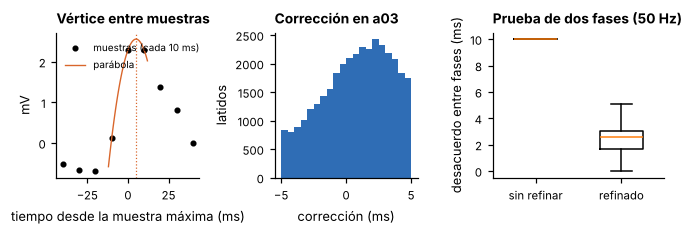

In [14]:
ecg, fs = load_ecg("a03")
x = apply_zero_phase(ecg, sos)
qrs = load_qrs("a03")
off, sign = qrs_reference(x, qrs, fs)
k = np.rint(r_peaks_from_marks(x, qrs, fs, off, sign, refine=False)[0] * fs).astype(int)
kr, _ = refine_peaks_parabolic(sign * x, k)
j = int(np.argmax(np.abs(kr - k)[1000:2000])) + 1000      # un latido con corrección grande
c = k[j]
fig, ax = plt.subplots(1, 3, figsize=(ANCHO, 2.2), gridspec_kw={"width_ratios": [1, 1, 1.2]})
tt = np.arange(c - 4, c + 5)
ax[0].plot((tt - c) * 10, x[tt], "o", color="black", ms=3, label="muestras (cada 10 ms)")
y0, y1, y2 = x[c - 1], x[c], x[c + 1]
a_, b_ = (y0 - 2 * y1 + y2) / 2, (y2 - y0) / 2
u = np.linspace(-1.2, 1.2, 100)
ax[0].plot(u * 10, a_ * u ** 2 + b_ * u + y1, color=APNEA, label="parábola")
ax[0].axvline((kr[j] - c) * 10, color=APNEA, ls=":", lw=0.8)
ax[0].set(xlabel="tiempo desde la muestra máxima (ms)", ylabel="mV", title="Vértice entre muestras")
ax[0].legend(loc="upper left", fontsize=6.5)
ax[1].hist(10 * (kr - k), bins=np.arange(-5, 5.5, 0.5), color=NORMAL)
ax[1].set(xlabel="corrección (ms)", ylabel="latidos", title="Corrección en a03")

fases = []
for rec in DEV[:12]:
    ecg_, fs_ = load_ecg(rec)
    x_ = apply_zero_phase(ecg_, sos)
    q_ = load_qrs(rec)
    o_, s_ = qrs_reference(x_, q_, fs_)
    tf = two_phase_peaks(x_, q_, fs_, o_, s_)
    fases.append(pd.DataFrame({"sin refinar": 1000 * np.abs(tf.par - tf.impar),
                               "refinado": 1000 * np.abs(tf.par_ref - tf.impar_ref)}))
fases = pd.concat(fases)
ax[2].boxplot([fases["sin refinar"], fases["refinado"]], showfliers=False, widths=0.5)
ax[2].set_xticks([1, 2]); ax[2].set_xticklabels(["sin refinar", "refinado"])
ax[2].set(ylabel="desacuerdo entre fases (ms)", title="Prueba de dos fases (50 Hz)")
fig.tight_layout()
save(fig, "02_refinamiento")
fases.agg(["median", "mean"]).round(2)

**Cómo se verifica sin una referencia de mayor resolución.** Se arma una prueba de dos fases: el ECG se baja a 50 Hz tomando las muestras pares por un lado y las impares por otro. Cada latido queda medido en dos grillas corridas 10 ms. Si los dos tiempos coinciden después de refinar, el refinamiento recupera la posición entre muestras. El desacuerdo medio baja de ~10 ms a unos pocos ms.

**¿Importa para la hipótesis?** El error de cuantización es como un ruido blanco agregado al RR: se reparte en todas las frecuencias. En la banda lenta de la feature (0,01–0,05 Hz), donde está la oscilación de la apnea, su potencia es despreciable frente a la del RR:

In [15]:
t_ent = r_peaks_from_marks(x, qrs, fs, off, sign, refine=False)[0]
t_ref = r_peaks_from_marks(x, qrs, fs, off, sign, refine=True)[0]
n = min(len(t_ent), len(t_ref))
tr, rr_ref, _ = clean_rr(t_ref)
_, rr_ent, _ = clean_rr(t_ent)
m = min(len(rr_ref), len(rr_ent))
err = (rr_ent[:m] - rr_ref[:m])
grid = np.arange(tr[0], tr[m - 1], 0.5)
fr, p_rr = welch(np.interp(grid, tr[:m], rr_ref[:m]), fs=2, nperseg=240)
_, p_err = welch(np.interp(grid, tr[:m], err), fs=2, nperseg=240)
banda = (fr >= 0.01) & (fr <= 0.05)
print(f"a03 · potencia del error de cuantización / potencia del RR en 0,01–0,05 Hz: "
      f"{100 * p_err[banda].sum() / p_rr[banda].sum():.3f} %; en 0,15–0,4 Hz: "
      f"{100 * p_err[(fr >= 0.15) & (fr <= 0.4)].sum() / p_rr[(fr >= 0.15) & (fr <= 0.4)].sum():.1f} %")

a03 · potencia del error de cuantización / potencia del RR en 0,01–0,05 Hz: 0.033 %; en 0,15–0,4 Hz: 1.7 %


Para la feature de este trabajo el refinamiento casi no cambia nada; sí pesa en la banda respiratoria y en índices latido a latido como el RMSSD. Se mantiene porque no cuesta nada y deja una serie RR correcta para cualquier otro uso.

## 4. Limpieza de la serie RR

Aun con la mejor fuente quedan intervalos que no son un latido normal tras otro: latidos perdidos o de más, y **latidos ectópicos** (un latido prematuro que deja un RR corto seguido de uno largo). Las reglas (`src/qrs/rr_clean.py`):

1. Un RR fuera de **0,3–2 s** (200 a 30 latidos por minuto) es imposible en reposo: se corrige.
2. Un RR que se aparta más de un **20 %** de la mediana de sus 11 vecinos se corrige (ectópico o error de detección).
3. Los RR corregidos se reemplazan por **interpolación lineal** entre los válidos vecinos.
4. Un minuto con más de **20 %** de RR corregidos se excluye: ahí la serie es más interpolación que dato.

¿Por qué 20 %? La figura muestra cuánto se aparta cada RR de la mediana de sus vecinos, en todos los latidos de desarrollo con el detector propio mejorado.

RR a menos de 10 % de la mediana: 97.2 % · a más de 20 %: 0.76 %


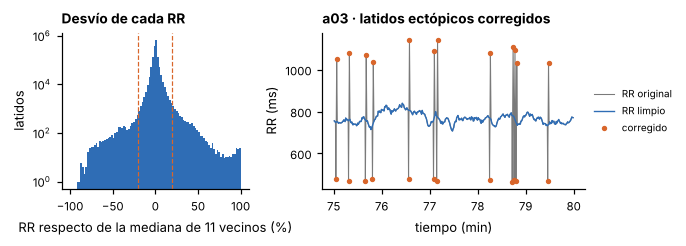

In [16]:
def desvios(rec):
    rr = np.diff(record_beats(rec, "pt")["t_r"])
    med = pd.Series(np.where((rr < 0.3) | (rr > 2), np.nan, rr)).rolling(11, center=True, min_periods=1).median()
    return (rr / med.to_numpy() - 1)

with ProcessPoolExecutor(4) as ex:
    dv = np.concatenate(list(ex.map(desvios, DEV)))
fig, ax = plt.subplots(1, 2, figsize=(ANCHO, 2.3), gridspec_kw={"width_ratios": [1, 1.4]})
ax[0].hist(100 * dv[np.isfinite(dv)], bins=np.arange(-100, 101, 2), color=NORMAL)
for v in (-20, 20):
    ax[0].axvline(v, color=APNEA, ls="--", lw=0.8)
ax[0].set(yscale="log", xlabel="RR respecto de la mediana de 11 vecinos (%)", ylabel="latidos",
          title="Desvío de cada RR")
b = record_beats("a03", "pt")
t, rr_c, corr = clean_rr(b["t_r"])
rr_raw = np.diff(b["t_r"])
sel = (t >= 75 * 60) & (t < 80 * 60)
ax[1].plot(t[sel] / 60, 1000 * rr_raw[sel], color=GRIS, lw=0.7, label="RR original")
ax[1].plot(t[sel] / 60, 1000 * rr_c[sel], color=NORMAL, lw=0.9, label="RR limpio")
ax[1].plot(t[sel & corr] / 60, 1000 * rr_raw[sel & corr], "o", color=APNEA, ms=2.5, label="corregido")
ax[1].set(xlabel="tiempo (min)", ylabel="RR (ms)", title="a03 · latidos ectópicos corregidos")
ax[1].legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=6.5)
fig.tight_layout()
save(fig, "02_limpieza_rr")
dvf = dv[np.isfinite(dv)]
print(f"RR a menos de 10 % de la mediana: {100 * np.mean(np.abs(dvf) < 0.1):.1f} % · "
      f"a más de 20 %: {100 * np.mean(np.abs(dvf) > 0.2):.2f} %")

**Qué se ve.** Casi todos los RR están a menos de 10 % de la mediana de sus vecinos (el número exacto se imprime arriba): la frecuencia cardíaca cambia de a poco de un latido a otro. Más allá de ±20 % la distribución es casi plana y tiene picos propios, que son errores: +100 % es un latido perdido (el RR se duplica), −50 % un latido de más en el medio y −80 % una onda T marcada como latido. Solo ~1 % de los RR queda fuera de ±20 %. El umbral de 20 % queda entre el cuerpo de la distribución y esas colas. A la derecha, los ectópicos de `a03` reemplazados por interpolación: el RR limpio conserva la variación lenta y la respiratoria.

## 5. Resumen

| Paso | Decisión | Por qué |
|---|---|---|
| Filtro | Butterworth 0,5–45 Hz, orden 3, ida y vuelta | Saca la deriva y el ruido > 45 Hz (con un cero en 50 Hz); es el menor orden que respeta el latido |
| Latidos | Detector propio (Pan-Tompkins) mejorado, en todos los registros | Las marcas de la base pierden latidos en algunos registros; el detector clásico marcaba tramos sin ECG y ondas T altas. Con cinco cambios, el detector propio no deja más RR imposibles que la base en ningún registro de desarrollo, y la revisión manual lo confirma |
| Tolerancia de comparación | 100 ms | Cuando las fuentes coinciden lo hacen a < 30 ms; la tolerancia no cambia el resultado |
| Refinamiento | Parábola de 3 puntos | Baja el error de cuantización de ~10 a pocos ms; en la banda de la feature su efecto es despreciable |
| Limpieza del RR | 0,3–2 s y ±20 % de la mediana de 11 vecinos; interpolación lineal; se excluyen los minutos con > 20 % corregido | El 20 % separa la variación normal de los ectópicos y errores |

Lo nuevo respecto de la primera versión es el **detector propio mejorado**, que reemplaza a las marcas de la base. Su efecto sobre la detección de apnea se mide en `04`.